In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import snowflake.connector
import sys, os
sys.path.insert(0, '../../')
from ingestion.utils.helpers import get_snowflake_config

plt.style.use('dark_background')
sns.set_palette("husl")

conn = snowflake.connector.connect(**get_snowflake_config())
df = pd.read_sql("""
    SELECT DATE, SYMBOL, CLOSE, RETURN, VOL_5D, VOL_20D, RSI_14, MA_5D, MA_20D
    FROM ANALYTICS.FACT_FEATURES
    WHERE RETURN IS NOT NULL AND VOL_5D IS NOT NULL
    ORDER BY DATE
""", conn)
conn.close()
df['DATE'] = pd.to_datetime(df['DATE'])
print(df.shape)
df.head()

Matplotlib is building the font cache; this may take a moment.
C:\Users\Hp\AppData\Local\Temp\ipykernel_12004\1624078650.py:14: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql("""


(4240, 9)


,DATE,SYMBOL,CLOSE,RETURN,VOL_5D,VOL_20D,RSI_14,MA_5D,MA_20D
0,2023-01-04,GBPUSD,1.196974,-0.007720,0.002107,0.002107,0.000000,1.205098,1.205098
1,2023-01-04,EURGBP,0.880890,-0.004768,0.004147,0.004147,18.689850,0.883380,0.883380
2,2023-01-04,USDCHF,0.935800,0.012771,0.008877,0.008877,100.000000,0.927867,0.927867
3,2023-01-04,EURAUD,1.568040,-0.000535,0.000505,0.000505,24.994677,1.568507,1.568507
4,2023-01-04,EURUSD,1.054685,-0.012255,0.006552,0.006552,0.000000,1.064477,1.064477


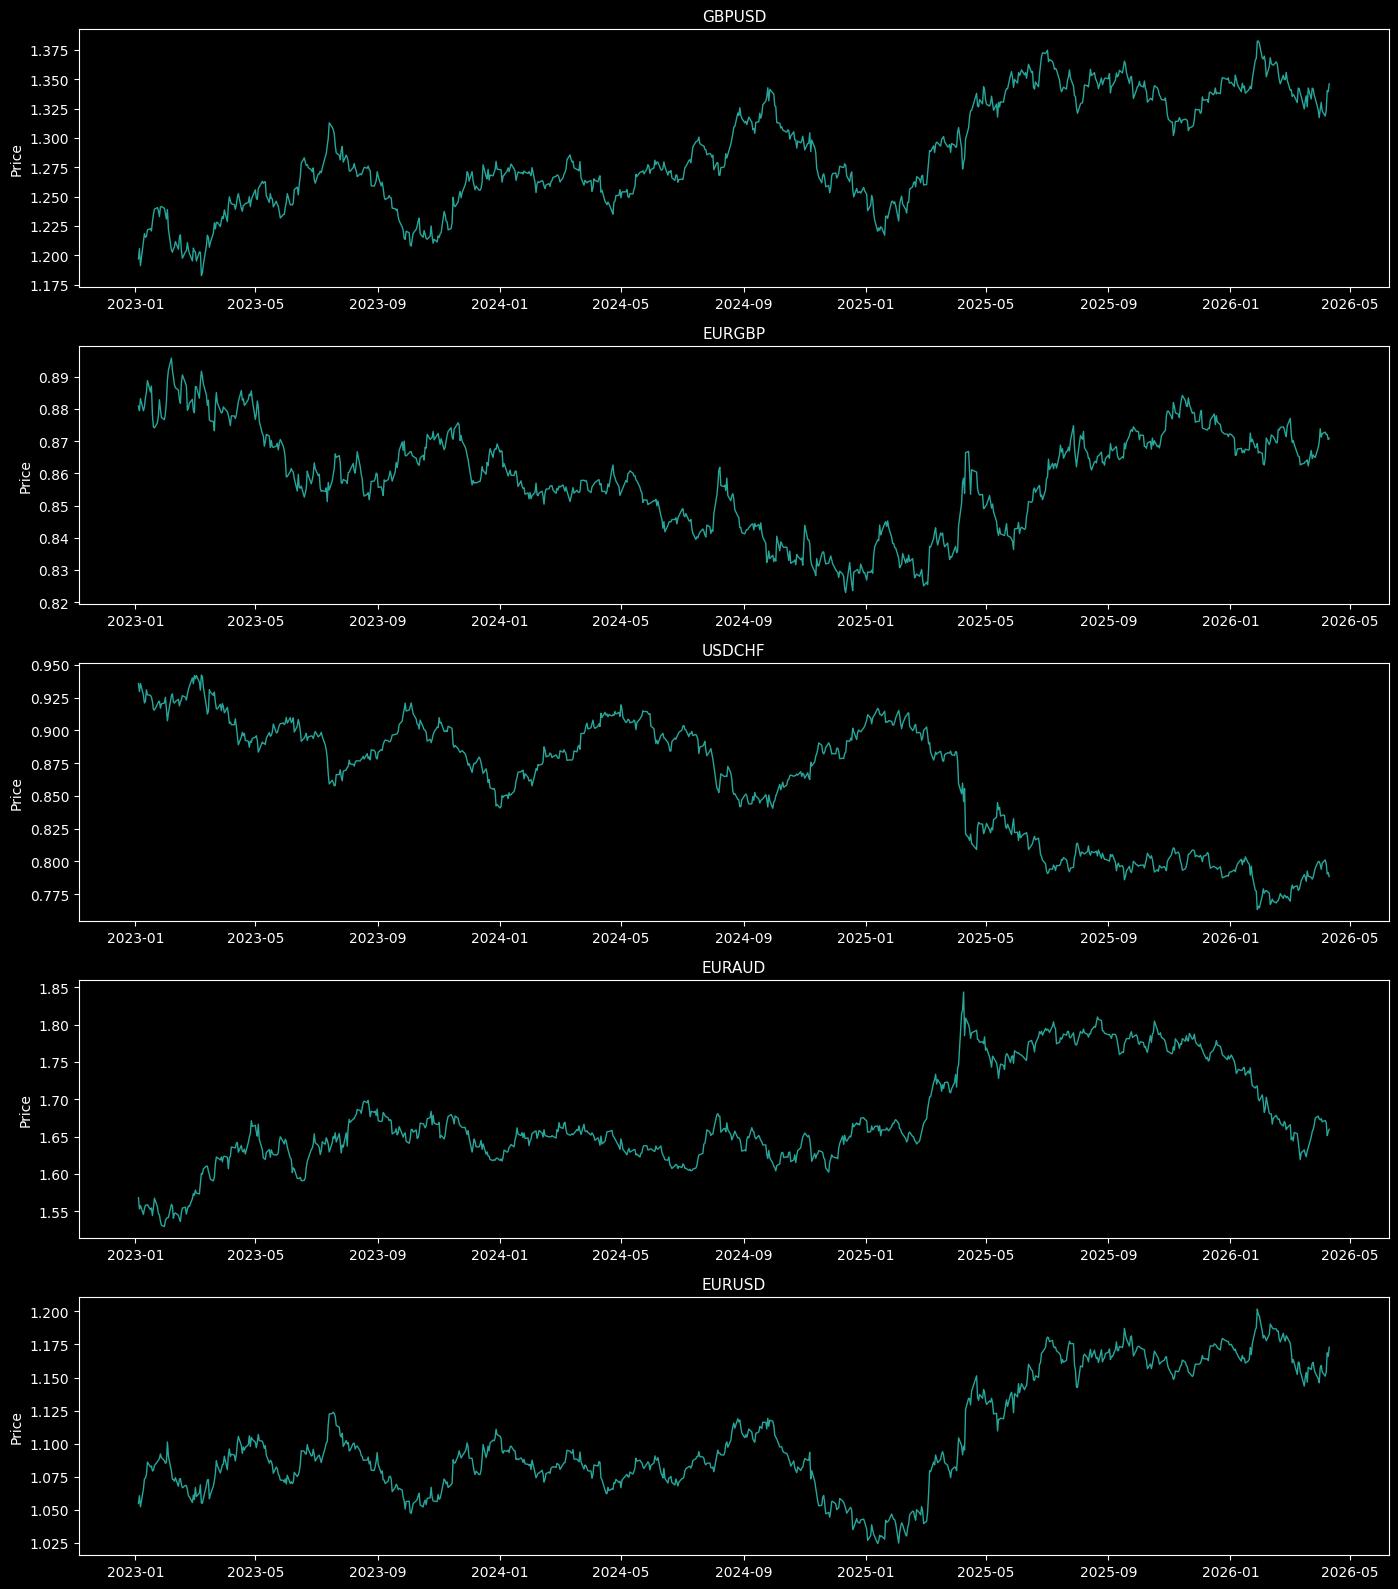

In [2]:
fig, axes = plt.subplots(5, 1, figsize=(14, 16))
for i, sym in enumerate(df['SYMBOL'].unique()):
    d = df[df['SYMBOL'] == sym]
    axes[i].plot(d['DATE'], d['CLOSE'], linewidth=1, color='#26A69A')
    axes[i].set_title(sym, fontsize=11)
    axes[i].set_ylabel('Price')
plt.tight_layout()
plt.show()

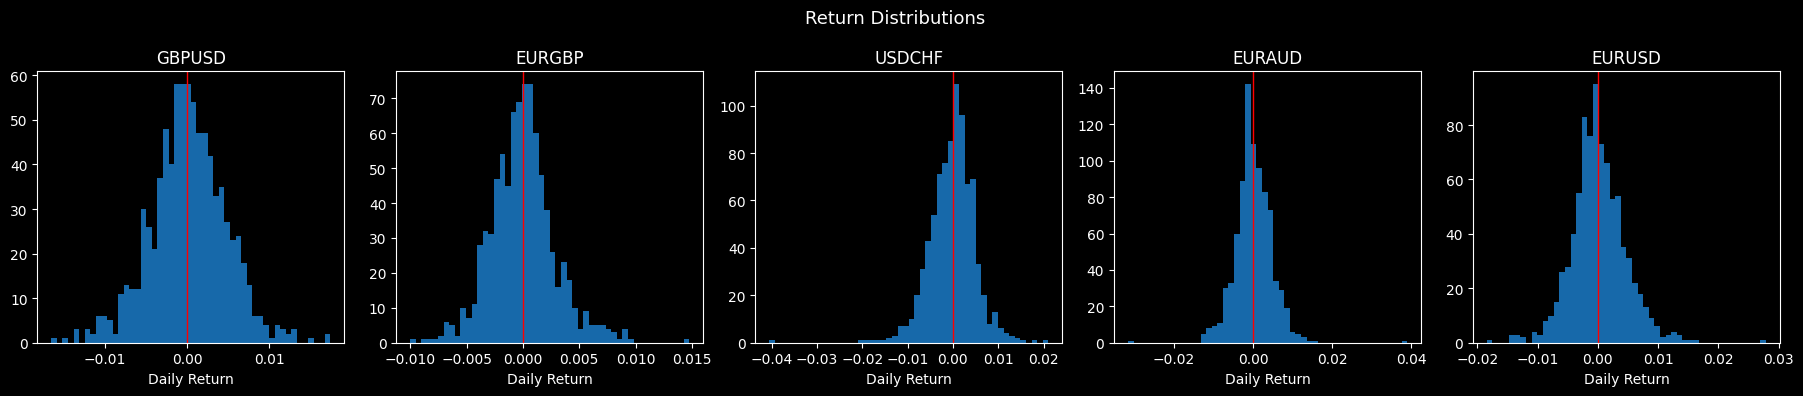

In [3]:
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for i, sym in enumerate(df['SYMBOL'].unique()):
    d = df[df['SYMBOL'] == sym]
    axes[i].hist(d['RETURN'], bins=50, color='#2196F3', alpha=0.7)
    axes[i].axvline(0, color='red', linewidth=1)
    axes[i].set_title(sym)
    axes[i].set_xlabel('Daily Return')
plt.suptitle('Return Distributions', fontsize=13)
plt.tight_layout()
plt.show()

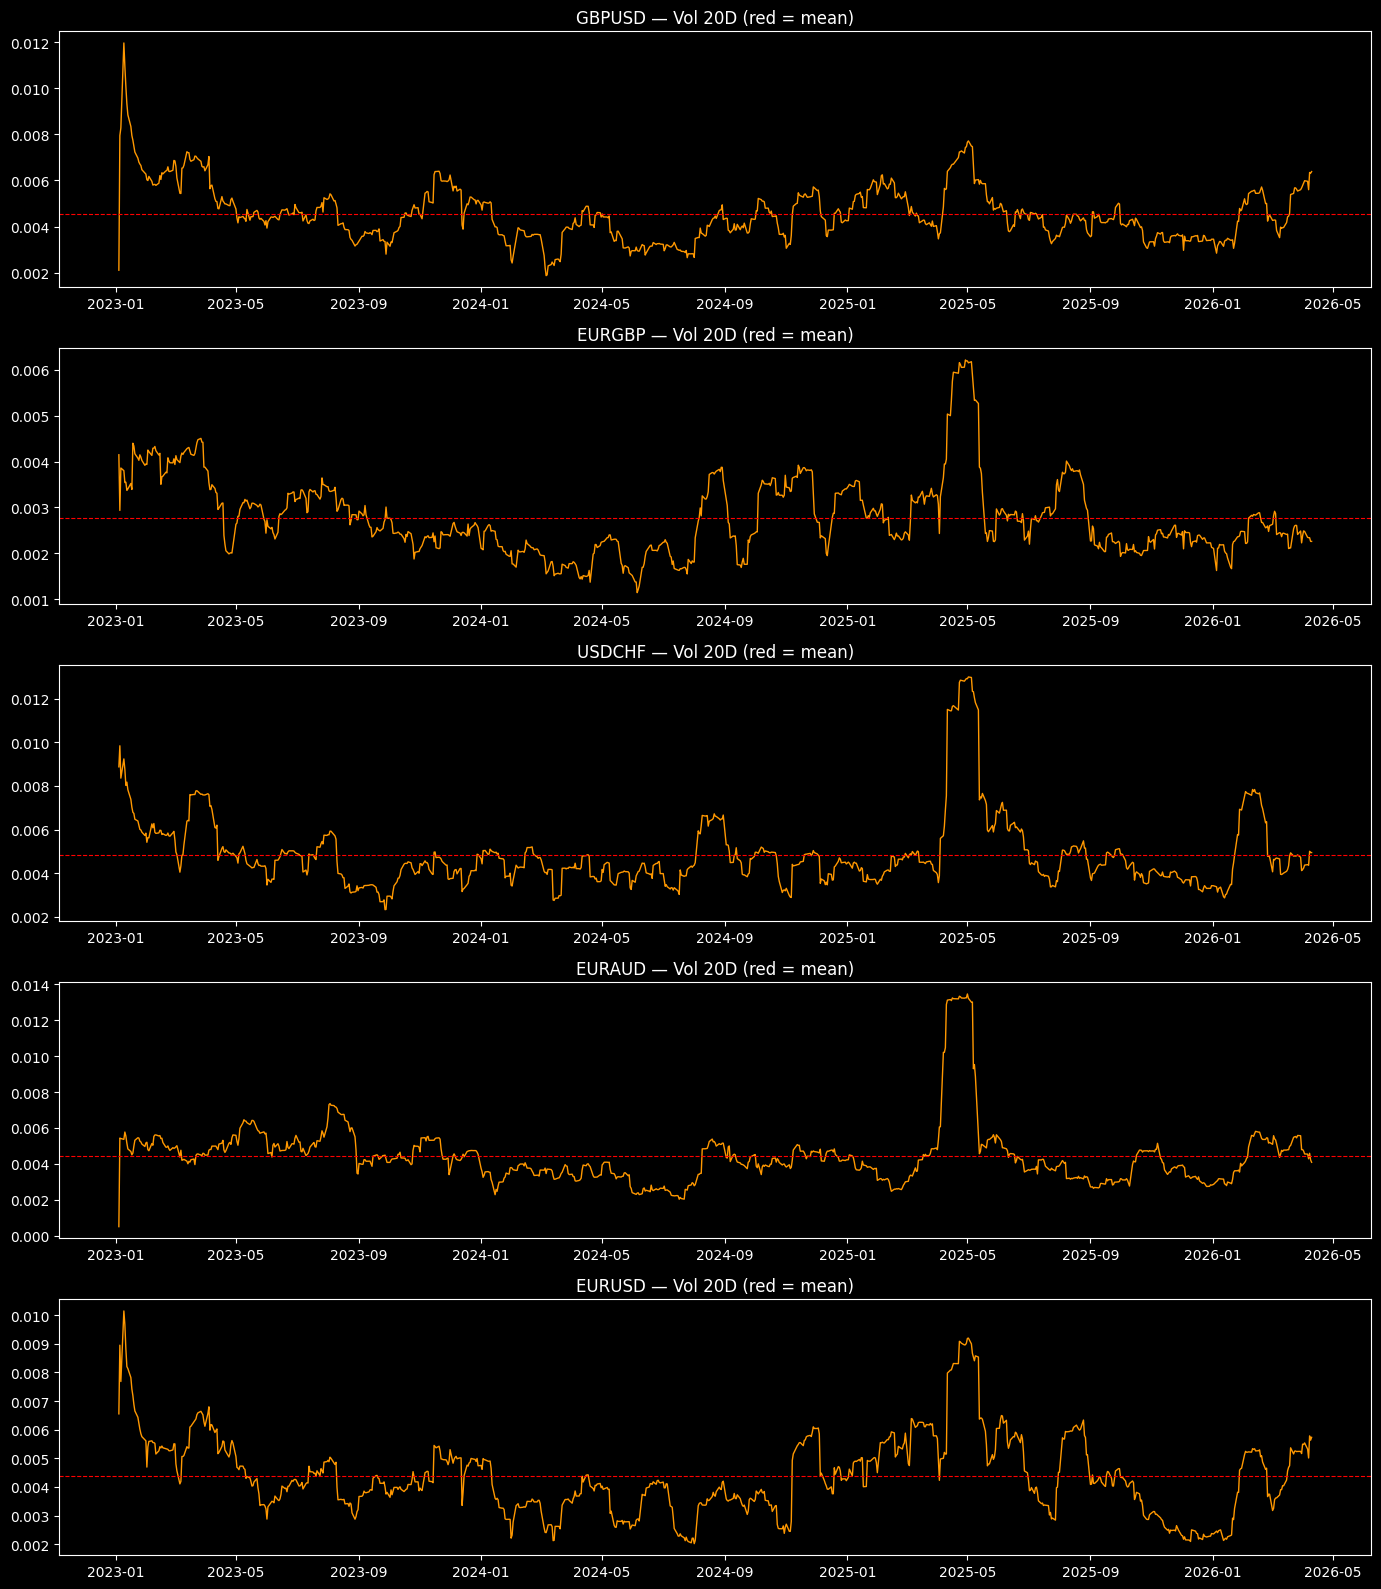

In [4]:
fig, axes = plt.subplots(5, 1, figsize=(14, 16))
for i, sym in enumerate(df['SYMBOL'].unique()):
    d = df[df['SYMBOL'] == sym]
    axes[i].plot(d['DATE'], d['VOL_20D'], linewidth=1, color='#FF9800')
    axes[i].axhline(d['VOL_20D'].mean(), color='red', linestyle='--', linewidth=0.8)
    axes[i].set_title(f"{sym} — Vol 20D (red = mean)")
plt.tight_layout()
plt.show()

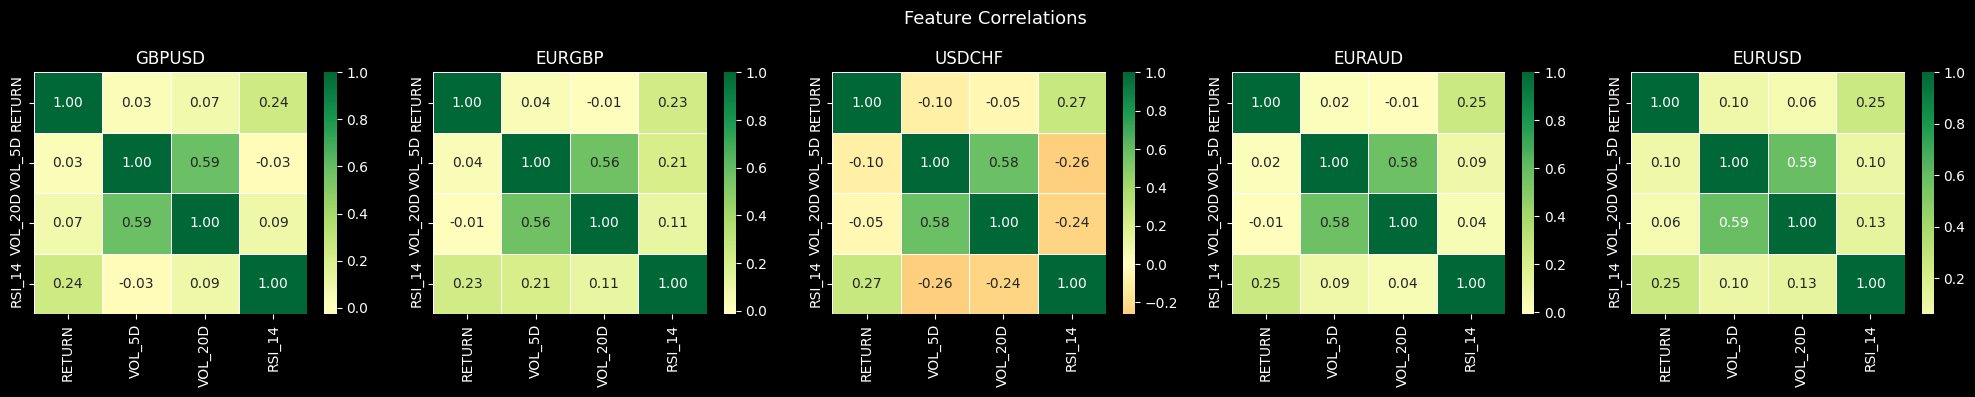

In [5]:
symbols = df['SYMBOL'].unique()
fig, axes = plt.subplots(1, len(symbols), figsize=(20, 4))
for i, sym in enumerate(symbols):
    d = df[df['SYMBOL'] == sym][['RETURN','VOL_5D','VOL_20D','RSI_14']].corr()
    sns.heatmap(d, ax=axes[i], annot=True, fmt='.2f',
                cmap='RdYlGn', center=0, linewidths=0.5)
    axes[i].set_title(sym)
plt.suptitle('Feature Correlations', fontsize=13)
plt.tight_layout()
plt.show()

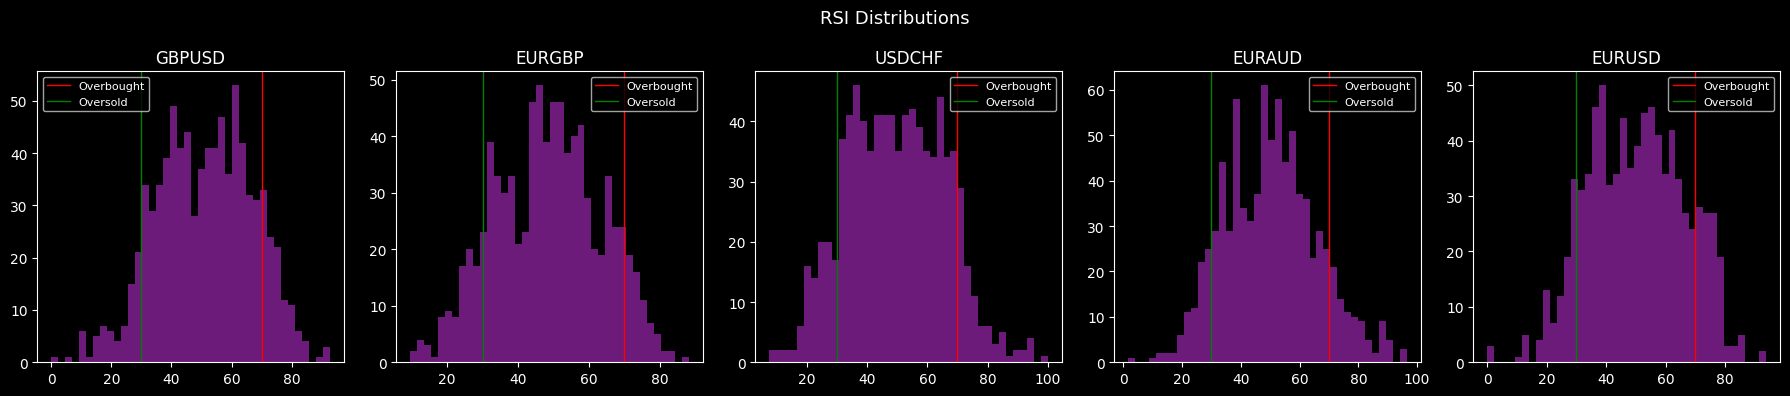

In [6]:
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for i, sym in enumerate(df['SYMBOL'].unique()):
    d = df[df['SYMBOL'] == sym]
    axes[i].hist(d['RSI_14'], bins=40, color='#9C27B0', alpha=0.7)
    axes[i].axvline(70, color='red', linewidth=1, label='Overbought')
    axes[i].axvline(30, color='green', linewidth=1, label='Oversold')
    axes[i].set_title(sym)
    axes[i].legend(fontsize=8)
plt.suptitle('RSI Distributions', fontsize=13)
plt.tight_layout()
plt.show()

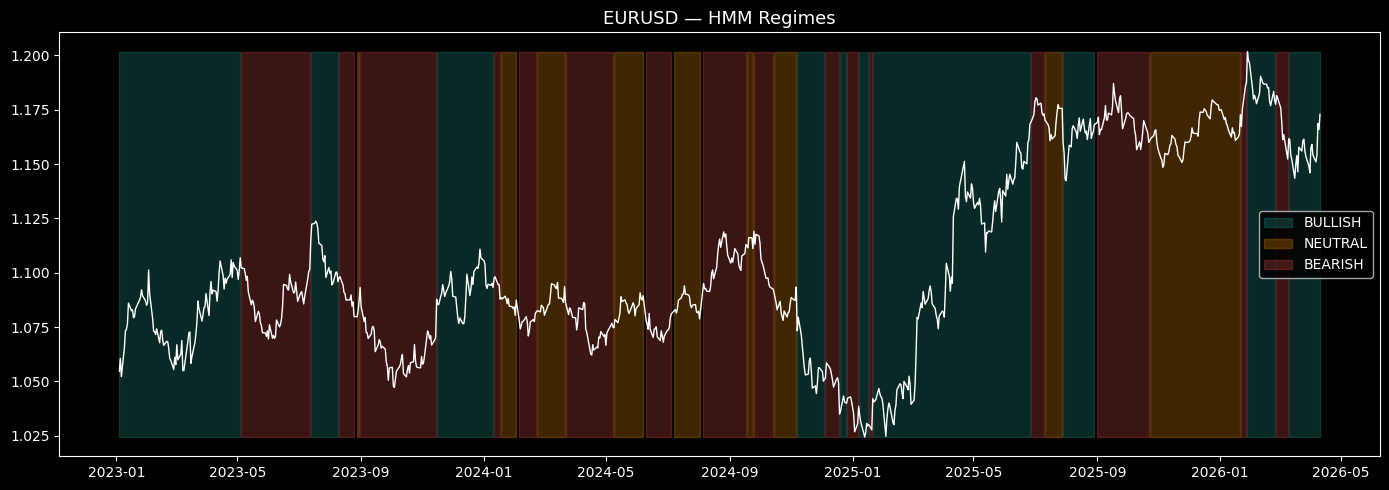

In [7]:
import joblib
import numpy as np
from sklearn.preprocessing import StandardScaler
from ml.features.feature_engineering import build_features

sym = 'EURUSD'
d   = df[df['SYMBOL'] == sym].copy()
X, d = build_features(d)

model  = joblib.load(f'../models/saved/{sym}_hmm.pkl')
scaler = joblib.load(f'../models/saved/{sym}_scaler.pkl')
labels = joblib.load(f'../models/saved/{sym}_labels.pkl')

X_scaled = scaler.transform(X)
regimes  = model.predict(X_scaled)
d['regime_raw'] = regimes
d['regime'] = d['regime_raw'].map(labels)

colors = {'BULLISH': '#26A69A', 'NEUTRAL': '#FF9800', 'BEARISH': '#EF5350'}

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(d['DATE'], d['CLOSE'], color='white', linewidth=1, zorder=2)
for regime, color in colors.items():
    mask = d['regime'] == regime
    ax.fill_between(d['DATE'], d['CLOSE'].min(), d['CLOSE'].max(),
                    where=mask, alpha=0.25, color=color, label=regime)
ax.set_title(f'{sym} — HMM Regimes', fontsize=13)
ax.legend()
plt.tight_layout()
plt.show()